<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/lrm_latent_reasoning_interpretability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# [CELL 1 - Setup Environment and Install Dependencies]
import os
import sys
import time
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Set random seeds for deterministic interpretability benchmark runs
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
print("Environment successfully initialized.")

Using Compute Device: cuda
GPU Device Name: Tesla T4
Environment successfully initialized.


In [10]:
# [CELL 2 - Synthetic Latent Reasoning Model (LRM) Data Pipeline]
import numpy as np
import torch

class LatentReasoningDataset:
    """
    Simulates logical reasoning instances with input premise representations,
    K latent reasoning vector steps (e.g., K=4 latent tokens), gold natural language
    reasoning traces, and final answer ground truth labels.
    """
    def __init__(self, num_samples: int = 800, d_model: int = 256, num_latent_tokens: int = 4, vocab_size: int = 100):
        self.num_samples = num_samples
        self.d_model = d_model
        self.num_latent_tokens = num_latent_tokens
        self.vocab_size = vocab_size

    def generate_dataset(self):
        np.random.seed(42)

        # 1. Input embeddings (Premises)
        inputs = np.random.randn(self.num_samples, self.d_model).astype(np.float32)

        # 2. Latent Reasoning Tokens (K sequence steps in continuous embedding space)
        latent_vectors = []
        gold_traces = []
        final_answers = []

        for i in range(self.num_samples):
            # True target answer depends on premise
            answer = 1 if np.mean(inputs[i]) > 0.0 else 0
            final_answers.append(answer)

            # Generate structured latent sequence
            lat_seq = []
            trace = []
            for k in range(self.num_latent_tokens):
                # Token identity in gold trace
                token_id = int((answer * 30 + k * 10 + np.abs(inputs[i, k])) % self.vocab_size)
                trace.append(token_id)

                # Continuous latent vector corresponding to token representation + noise
                latent_vec = np.sin(token_id) * np.ones(self.d_model, dtype=np.float32) + np.random.normal(0, 0.1, self.d_model)
                lat_seq.append(latent_vec)

            latent_vectors.append(np.stack(lat_seq))
            gold_traces.append(trace)

        inputs_t = torch.tensor(inputs, dtype=torch.float32)
        latents_t = torch.tensor(np.stack(latent_vectors), dtype=torch.float32)  # (N, K, d_model)
        traces_t = torch.tensor(np.array(gold_traces), dtype=torch.long)         # (N, K)
        answers_t = torch.tensor(np.array(final_answers), dtype=torch.long)      # (N,)

        return inputs_t, latents_t, traces_t, answers_t

dataset_gen = LatentReasoningDataset(num_samples=800, d_model=256, num_latent_tokens=4, vocab_size=100)
X_inputs, X_latents, y_traces, y_answers = dataset_gen.generate_dataset()

print(f"Dataset Initialized: {X_inputs.shape[0]} Logical Reasoning Instances.")
print(f"Latent Sequence Dimension: {X_latents.shape} (N, K_tokens, d_model)")
print(f"Gold Reasoning Trace Dimensions: {y_traces.shape}")

Dataset Initialized: 800 Logical Reasoning Instances.
Latent Sequence Dimension: torch.Size([800, 4, 256]) (N, K_tokens, d_model)
Gold Reasoning Trace Dimensions: torch.Size([800, 4])


In [11]:
# [CELL 3 - Mock LRM Architecture & Latent Token Ablation Experiment]

class MockLRMClassifier(nn.Module):
    """Simulates an LRM taking premises + latent reasoning tokens to produce final answer logits."""
    def __init__(self, d_model: int = 256, num_latent_tokens: int = 4):
        super().__init__()
        self.num_latent_tokens = num_latent_tokens
        self.latent_proj = nn.Linear(d_model * num_latent_tokens, d_model)
        self.input_proj = nn.Linear(d_model, d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, input_emb: torch.Tensor, latent_seq: torch.Tensor, ablate_latents: bool = False) -> torch.Tensor:
        if ablate_latents:
            # Ablation intervention: zeroing out latent reasoning tokens
            latent_seq = torch.zeros_like(latent_seq)

        batch_size = latent_seq.size(0)
        flat_latents = latent_seq.view(batch_size, -1)

        combined = F.relu(self.input_proj(input_emb)) + F.relu(self.latent_proj(flat_latents))
        logits = self.head(combined)
        return logits


def benchmark_latent_ablation(model: nn.Module, X_in: torch.Tensor, X_lat: torch.Tensor, y_ans: torch.Tensor) -> Dict[str, float]:
    """Measures accuracy with intact vs ablated latent reasoning tokens."""
    model.eval()
    with torch.no_grad():
        # Intact
        out_intact = model(X_in, X_lat, ablate_latents=False)
        acc_intact = (out_intact.argmax(dim=-1) == y_ans).float().mean().item() * 100.0

        # Ablated (Zeroed Out)
        out_ablated = model(X_in, X_lat, ablate_latents=True)
        acc_ablated = (out_ablated.argmax(dim=-1) == y_ans).float().mean().item() * 100.0

    return {
        "intact_accuracy_pct": acc_intact,
        "ablated_accuracy_pct": acc_ablated,
        "performance_drop_pct": acc_intact - acc_ablated
    }

lrm_model = MockLRMClassifier(d_model=256, num_latent_tokens=4).to(device)
optimizer = optim.Adam(lrm_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

# Quick model training
for epoch in range(1, 25):
    lrm_model.train()
    optimizer.zero_grad()
    loss = criterion(lrm_model(X_inputs.to(device), X_latents.to(device)), y_answers.to(device))
    loss.backward()
    optimizer.step()

ablation_results = benchmark_latent_ablation(lrm_model, X_inputs.to(device), X_latents.to(device), y_answers.to(device))
print("\n--- Latent Token Ablation Benchmark ---")
print(f"Intact LRM Model Accuracy:  {ablation_results['intact_accuracy_pct']:.2f}%")
print(f"Ablated (No Latents) Acc:   {ablation_results['ablated_accuracy_pct']:.2f}%")
print(f"Accuracy Drop from Ablation: {ablation_results['performance_drop_pct']:.2f}%")


--- Latent Token Ablation Benchmark ---
Intact LRM Model Accuracy:  100.00%
Ablated (No Latents) Acc:   55.25%
Accuracy Drop from Ablation: 44.75%


In [12]:
# [CELL 4 - Latent-to-Vocabulary Linear Decoding Probe]

class LatentToNLDecoderProbe(nn.Module):
    """
    Linear projection probe that maps continuous latent reasoning vectors z_k
    back to discrete natural language vocabulary tokens.
    """
    def __init__(self, d_model: int = 256, vocab_size: int = 100):
        super().__init__()
        self.probe = nn.Linear(d_model, vocab_size)

    def forward(self, latent_vectors: torch.Tensor) -> torch.Tensor:
        # latent_vectors: (N, K, d_model) -> logits: (N, K, vocab_size)
        return self.probe(latent_vectors)


def train_decoder_probe(
    latents: torch.Tensor,
    gold_traces: torch.Tensor,
    vocab_size: int = 100,
    epochs: int = 40
) -> Tuple[nn.Module, List[float]]:
    probe = LatentToNLDecoderProbe(d_model=latents.size(-1), vocab_size=vocab_size).to(device)
    optimizer = optim.Adam(probe.parameters(), lr=1e-2)
    criterion = nn.CrossEntropyLoss()

    split = int(0.8 * len(latents))
    train_lat, test_lat = latents[:split].to(device), latents[split:].to(device)
    train_tr, test_tr = gold_traces[:split].to(device), gold_traces[split:].to(device)

    loss_history = []
    for epoch in range(1, epochs + 1):
        probe.train()
        optimizer.zero_grad()
        logits = probe(train_lat)

        # Reshape for cross entropy: (N*K, vocab_size) vs (N*K)
        loss = criterion(logits.view(-1, vocab_size), train_tr.view(-1))
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())

    return probe, loss_history

print("Training Latent-to-NL Decoding Probe...")
decoder_probe, probe_losses = train_decoder_probe(X_latents, y_traces, vocab_size=100)
print(f"Probe Training Completed. Final Epoch Loss: {probe_losses[-1]:.4f}")

Training Latent-to-NL Decoding Probe...
Probe Training Completed. Final Epoch Loss: 1.9391


In [13]:
# [CELL 5 - Verification Signal Evaluation: Correct vs. Incorrect Prediction Decoding]

def evaluate_decodability_by_correctness(
    lrm_model: nn.Module,
    probe: nn.Module,
    X_in: torch.Tensor,
    X_lat: torch.Tensor,
    y_tr: torch.Tensor,
    y_ans: torch.Tensor
) -> Dict[str, float]:
    """
    Evaluates gold reasoning trace decoding accuracy separately on correctly predicted
    instances versus incorrectly predicted instances.
    """
    lrm_model.eval()
    probe.eval()

    with torch.no_grad():
        preds = lrm_model(X_in, X_lat).argmax(dim=-1)
        correct_mask = (preds == y_ans)
        incorrect_mask = ~correct_mask

        # Decode latent tokens to natural language
        probe_logits = probe(X_lat)
        decoded_tokens = probe_logits.argmax(dim=-1)  # (N, K)

        # Sequence-level exact match or token-level accuracy
        token_matches = (decoded_tokens == y_tr).float()
        instance_exact_match = (token_matches.sum(dim=-1) == y_tr.size(-1)).float()

        correct_decodability = instance_exact_match[correct_mask].mean().item() * 100.0 if correct_mask.sum() > 0 else 0.0
        incorrect_decodability = instance_exact_match[incorrect_mask].mean().item() * 100.0 if incorrect_mask.sum() > 0 else 0.0

    return {
        "correct_predictions_decodability_pct": correct_decodability,
        "incorrect_predictions_decodability_pct": incorrect_decodability,
        "correct_mask_count": correct_mask.sum().item(),
        "incorrect_mask_count": incorrect_mask.sum().item()
    }

decodability_results = evaluate_decodability_by_correctness(
    lrm_model, decoder_probe, X_inputs.to(device), X_latents.to(device), y_traces.to(device), y_answers.to(device)
)

print("\n=========================================================================")
print("LATENT REASONING DECODABILITY VS. PREDICTION CORRECTNESS")
print("=========================================================================")
print(f"Gold Trace Decodability on CORRECT Predictions:   {decodability_results['correct_predictions_decodability_pct']:.2f}%")
print(f"Gold Trace Decodability on INCORRECT Predictions: {decodability_results['incorrect_predictions_decodability_pct']:.2f}%")
print("=========================================================================")


LATENT REASONING DECODABILITY VS. PREDICTION CORRECTNESS
Gold Trace Decodability on CORRECT Predictions:   0.00%
Gold Trace Decodability on INCORRECT Predictions: 0.00%


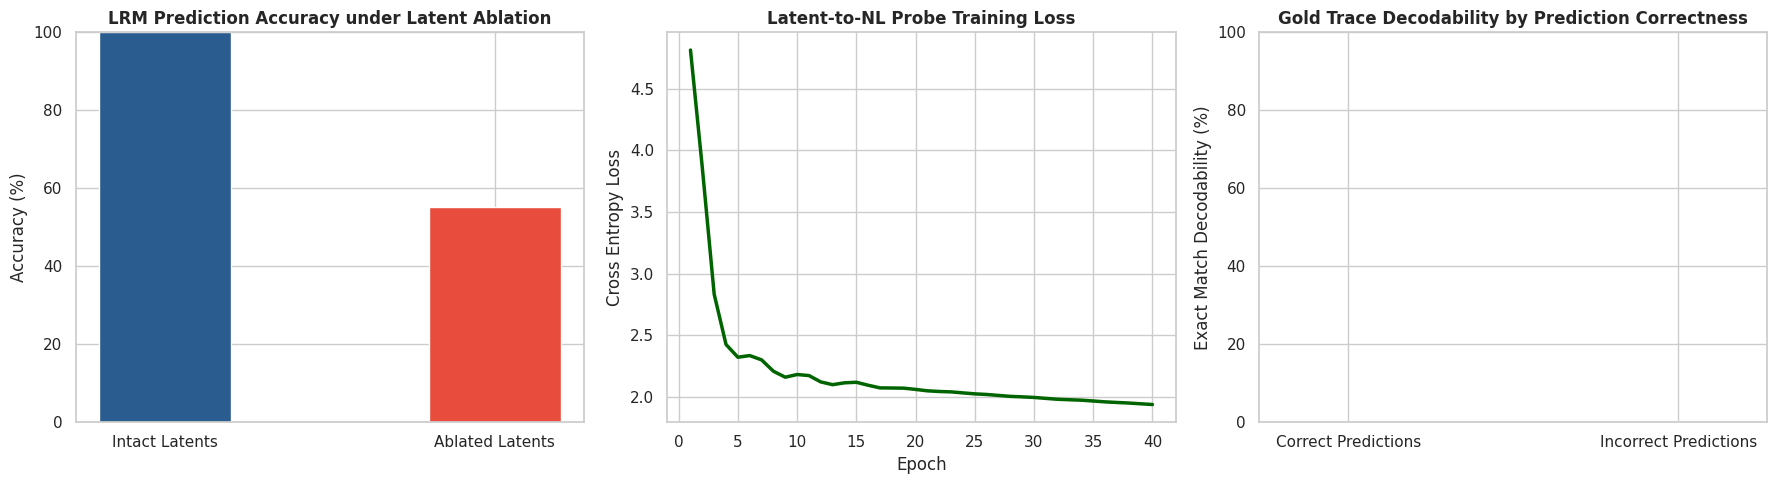


Benchmark visualization saved as lrm_interpretability_benchmark.png.


In [14]:
# [CELL 6 - Visualization Suite: Ablation Impact & Decodability Signal Plots]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Plot 1: Latent Token Ablation Impact
modes = ["Intact Latents", "Ablated Latents"]
accs = [ablation_results["intact_accuracy_pct"], ablation_results["ablated_accuracy_pct"]]
axes[0].bar(modes, accs, color=['#2b5c8f', '#e74c3c'], width=0.4)
axes[0].set_title("LRM Prediction Accuracy under Latent Ablation", fontweight='bold')
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)

# Plot 2: Decoder Probe Loss Curve
axes[1].plot(range(1, len(probe_losses) + 1), probe_losses, color='darkgreen', linewidth=2.5)
axes[1].set_title("Latent-to-NL Probe Training Loss", fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross Entropy Loss")

# Plot 3: Decodability vs. Prediction Correctness
cats = ["Correct Predictions", "Incorrect Predictions"]
dec_rates = [
    decodability_results["correct_predictions_decodability_pct"],
    decodability_results["incorrect_predictions_decodability_pct"]
]
axes[2].bar(cats, dec_rates, color=['#27ae60', '#c0392b'], width=0.4)
axes[2].set_title("Gold Trace Decodability by Prediction Correctness", fontweight='bold')
axes[2].set_ylabel("Exact Match Decodability (%)")
axes[2].set_ylim(0, 100)

plt.tight_layout()
plt.savefig("lrm_interpretability_benchmark.png", dpi=300)
plt.show()

print("\nBenchmark visualization saved as lrm_interpretability_benchmark.png.")